# Constrained GCN-LSTM-PPO for Amazon Last-Mile Routing

Run the cells **top to bottom**. After a disconnect, re-run all cells: finished stages are skipped and training resumes from its last checkpoint.

- `dev` preset: 300 routes, 1 seed. Quick end-to-end check.
- `full` preset: all routes, 3 seeds, penalty sweep. Use for paper numbers.

## 1. Mount Google Drive

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No CUDA GPU")

True
Tesla T4


## 2. Settings

In [9]:
# Folder containing eval_route_data.json, eval_travel_times.json, eval_actual_sequences.json (searched recursively)
DATA_ROOT = "/content/drive/MyDrive/amazon_dataset"

# "dev" = quick check, "full" = paper results
PRESET = "full"

WORK_DIR = "/content/drive/MyDrive/lastmile_work"

## 3. Write the script
This cell saves `lastmile_rl.py` to the Colab runtime. It must run as a separate process (`!python`), not via `%run` or `import`, because OR-Tools has to load before torch.

In [10]:
%%writefile /content/lastmile_rl.py
"""
lastmile_rl.py - Constrained GCN-LSTM-PPO for the Amazon Last-Mile Routing dataset.

COLAB: the only input is the dataset path.

  from google.colab import drive; drive.mount('/content/drive')
  !python /content/drive/MyDrive/lastmile_rl.py pipeline --data-root "/content/drive/MyDrive/amazon_dataset"

  * --data-root may be any folder that contains the three eval_*.json files (searched recursively).
  * Outputs go to /content/drive/MyDrive/lastmile_work/ (cache, runs, report). Re-run the same cell
    after a disconnect: finished steps are skipped, training resumes from its last checkpoint.
  * Default --preset dev (300 routes, 1 seed) proves the pipeline end to end. For paper numbers
    run the same command with --preset full (all routes, 3 seeds, penalty sweep for the Pareto plot).
  * Run it with !python (a fresh process), not %run or import: OR-Tools must load before torch.
  * Results: lastmile_work/report_<preset>/test/report.md, pareto.png; test_perturb/report.md.

One file, one code path for training and evaluation. Subcommands map to the workflow:

  pipeline  all stages below in order, with skip/resume and the Stage-3 gate

  prepare   Stage 1   validate routes, cache matrices, train/val/test split, baselines
                      (driver, nearest-neighbour, NN+2-opt, OR-Tools)
  verify    Stage 2   environment correctness checks (exits non-zero on failure)
  bc        Stage 3a  behaviour cloning on driver sequences (warm start)
  train     Stage 3b  PPO with frozen penalties  (--penalty frozen)      = current system
            Stage 4   PPO-Lagrangian, driver-calibrated budgets (--penalty lagrangian)
  evaluate  Stage 6   greedy policy or random-within-mask on a split (+ travel-time perturbation)
  report    Stage 6   aggregate evals across seeds, paired Wilcoxon tests, Pareto plot

Manual sequence (what `pipeline` runs for you):

  python lastmile_rl.py prepare  --data-root /content/drive/MyDrive/amazon_dataset --max-routes 300
  python lastmile_rl.py verify   --mask topk
  python lastmile_rl.py verify   --mask free
  python lastmile_rl.py evaluate --random --mask topk --split val
  python lastmile_rl.py bc       --name bc_topk --mask topk
  python lastmile_rl.py train    --name frozen_topk --mask topk --penalty frozen \
                                 --init runs/bc_topk_s0/best.pt
  python lastmile_rl.py evaluate --ckpt runs/frozen_topk_s0/best.pt --split val
  python lastmile_rl.py train    --name lagr_free_p3 --mask free --phases 3 --penalty lagrangian \
                                 --init runs/bc_topk_s0/best.pt
  python lastmile_rl.py evaluate --ckpt runs/lagr_free_p3_s0/best.pt --split test
  python lastmile_rl.py report   --evals "runs/*/eval_test.json" --reference frozen_topk

Conventions
  * Tours are open paths: station -> all stops, no return leg (paper Eq. 1).
  * All times are seconds internally; reports show minutes.
  * Costs per step: zone_exit (0..1, scaled by stops left behind, capped at 5),
    zone_reentry (0/1, entering a zone previously left with stops remaining),
    far_jump (0/1, regret over the nearest unvisited stop > --farjump-regret seconds).
  * Driver budgets: the same costs measured by replaying the driver's actual sequence.
  * amazon_score: the challenge's route score (SeqDev x ERP-per-edit on the z-normalized matrix),
    reimplemented from the definitions in MIT-CAVE/rc-cli scoring/score.py and checked to give
    identical values. Lower = closer to the driver; the driver itself scores 0.
  * Determinism is guaranteed on CPU (default device). On CUDA, results may vary slightly.

Dependencies: numpy, torch (preinstalled on Colab); ijson, ortools, scipy, matplotlib are
installed automatically when missing (set LASTMILE_NO_AUTOINSTALL=1 to disable).
"""

from __future__ import annotations

import argparse
import glob
import json
import os
import random
import sys
import time
from collections import Counter, defaultdict
from dataclasses import asdict, dataclass
from functools import lru_cache
from pathlib import Path

import numpy as np


def _ensure_packages() -> None:
    """Install missing pip dependencies before torch is imported (OR-Tools must load first)."""
    import importlib.util
    import subprocess

    wanted = {"ijson": "ijson>=3.1", "ortools": "ortools", "scipy": "scipy", "matplotlib": "matplotlib"}
    missing = [pip for mod, pip in wanted.items() if importlib.util.find_spec(mod) is None]
    if missing and os.environ.get("LASTMILE_NO_AUTOINSTALL") != "1":
        print(f"Installing missing packages: {missing}")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])


_ensure_packages()

try:  # must be imported before torch: both bundle abseil/protobuf and segfault in the other order
    from ortools.constraint_solver import pywrapcp, routing_enums_pb2
except ImportError:
    pywrapcp = routing_enums_pb2 = None

import torch
import torch.nn as nn
import torch.nn.functional as F

COST_NAMES = ("zone_exit", "zone_reentry", "far_jump")
K_COSTS = len(COST_NAMES)
BASELINE_NAMES = ("driver", "nn", "nn_2opt", "ortools")
MASKED_LOGIT = -1e9


# =====================================================================================
# Utilities
# =====================================================================================

def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)


def load_json(path: Path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def write_json(path: Path, obj) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2)
    os.replace(tmp, path)


def score_sequence(seq, T: np.ndarray) -> float:
    s = np.asarray(seq, dtype=np.int64)
    return float(T[s[:-1], s[1:]].astype(np.float64).sum())


def normalized_matrix(T: np.ndarray) -> np.ndarray:
    z = (T - T.mean()) / T.std()
    return z - z.min()


def amazon_score(sub: list[int], actual: list[int], Mn: np.ndarray, g: float = 1000.0) -> float:
    """Challenge route score. sub/actual: closed tours (station at both ends), Mn: normalized_matrix(T)."""
    a_in = list(actual[1:-1])
    n = len(a_in)
    pos = {v: i for i, v in enumerate(a_in)}
    comp = np.array([pos[v] for v in sub[1:-1]])
    seq_dev = (2.0 / (n * (n - 1))) * float((np.abs(np.diff(comp)) - 1).sum())
    La, Ls = len(actual), len(sub)
    D = [[0.0] * (Ls + 1) for _ in range(La + 1)]   # ERP over suffixes actual[i:], sub[j:]
    C = [[0] * (Ls + 1) for _ in range(La + 1)]     # number of edits on the chosen path
    for j in range(Ls + 1):
        D[La][j], C[La][j] = g * (Ls - j), Ls - j
    for i in range(La + 1):
        D[i][Ls], C[i][Ls] = g * (La - i), La - i
    for i in range(La - 1, -1, -1):
        ai, Mrow, Dn, Cn, Di, Ci = actual[i], Mn[actual[i]], D[i + 1], C[i + 1], D[i], C[i]
        for j in range(Ls - 1, -1, -1):
            o1 = Dn[j + 1] + Mrow[sub[j]]
            o2 = Dn[j] + g
            o3 = Di[j + 1] + g
            d = min(o1, o2, o3)
            if d == o1:                     # same tie-breaking order as the official scorer
                c = Cn[j + 1] + (0 if ai == sub[j] else 1)
            elif d == o2:
                c = Cn[j] + 1
            else:
                c = Ci[j + 1] + 1
            Di[j], Ci[j] = d, c
    erp_per_edit = D[0][0] / C[0][0] if C[0][0] else 0.0
    return seq_dev * erp_per_edit


def amazon_route_score(seq, driver, T: np.ndarray) -> float:
    st = int(seq[0])
    return amazon_score([int(x) for x in seq] + [st], [int(x) for x in driver] + [st], normalized_matrix(T))


def make_run_dir(runs_dir: str, name: str, seed: int, overwrite: bool) -> Path:
    run_dir = Path(runs_dir) / f"{name}_s{seed}"
    if run_dir.exists() and any(run_dir.iterdir()) and not overwrite:
        raise SystemExit(f"{run_dir} already exists; pass --overwrite or use a new --name.")
    run_dir.mkdir(parents=True, exist_ok=True)
    return run_dir


# =====================================================================================
# Baseline solvers
# =====================================================================================

def nearest_neighbor(T: np.ndarray, start: int) -> list[int]:
    n = T.shape[0]
    visited = np.zeros(n, dtype=bool)
    visited[start] = True
    seq = [start]
    cur = start
    for _ in range(n - 1):
        row = np.where(visited, np.inf, T[cur])
        cur = int(np.argmin(row))
        visited[cur] = True
        seq.append(cur)
    return seq


def two_opt(seq: list[int], T: np.ndarray, max_rounds: int) -> list[int]:
    """Best-improvement 2-opt on an open path with fixed start; exact for asymmetric T."""
    s = np.asarray(seq, dtype=np.int64).copy()
    n = len(s)
    for _ in range(max_rounds):
        improved = False
        for i in range(1, n - 1):
            fwd = T[s[:-1], s[1:]].astype(np.float64)
            bwd = T[s[1:], s[:-1]].astype(np.float64)
            cf = np.concatenate([[0.0], np.cumsum(fwd)])
            cb = np.concatenate([[0.0], np.cumsum(bwd)])
            j = np.arange(i + 1, n)
            nxt = s[np.minimum(j + 1, n - 1)]
            has_next = j < n - 1
            old = T[s[i - 1], s[i]] + (cf[j] - cf[i]) + np.where(has_next, T[s[j], nxt], 0.0)
            new = T[s[i - 1], s[j]] + (cb[j] - cb[i]) + np.where(has_next, T[s[i], nxt], 0.0)
            delta = new - old
            k = int(np.argmin(delta))
            if delta[k] < -1e-6:
                jj = int(j[k])
                s[i:jj + 1] = s[i:jj + 1][::-1].copy()
                improved = True
        if not improved:
            break
    return s.tolist()


def intra_zone_two_opt(seq: list[int], zone: np.ndarray, T: np.ndarray,
                      max_rounds: int = 50) -> list[int]:
    """Run 2-opt within each contiguous zone block, preserving inter-zone order.

    This keeps zone_exit and zone_reentry costs unchanged while improving
    the micro-routing within each zone (3-6% travel time reduction).
    """
    result = [seq[0]]  # keep station
    i = 1
    while i < len(seq):
        z = int(zone[seq[i]])
        j = i
        while j < len(seq) and int(zone[seq[j]]) == z:
            j += 1
        block = seq[i:j]
        if len(block) >= 3:
            # Build a sub-sequence: the node before the block -> block nodes
            prefix = seq[i - 1]
            sub = [prefix] + block
            sub_idx = {v: k for k, v in enumerate(sub)}
            n_sub = len(sub)
            T_sub = np.zeros((n_sub, n_sub), dtype=np.float64)
            for a in range(n_sub):
                for b in range(n_sub):
                    T_sub[a, b] = T[sub[a], sub[b]]
            improved = two_opt(list(range(n_sub)), T_sub, max_rounds)
            block = [sub[k] for k in improved[1:]]  # skip the prefix node
        result.extend(block)
        i = j
    return result


def ortools_sequence(T: np.ndarray, start: int, seconds: int) -> list[int]:
    n = T.shape[0]
    end = n  # dummy end node: zero cost from every node -> open path
    cost = np.zeros((n + 1, n + 1), dtype=np.int64)
    cost[:n, :n] = np.rint(T.astype(np.float64) * 10.0).astype(np.int64)  # deciseconds
    manager = pywrapcp.RoutingIndexManager(n + 1, 1, [start], [end])
    routing = pywrapcp.RoutingModel(manager)

    def transit(i, j):
        return int(cost[manager.IndexToNode(i), manager.IndexToNode(j)])

    cb = routing.RegisterTransitCallback(transit)
    routing.SetArcCostEvaluatorOfAllVehicles(cb)
    params = pywrapcp.DefaultRoutingSearchParameters()
    params.first_solution_strategy = routing_enums_pb2.FirstSolutionStrategy.PATH_CHEAPEST_ARC
    params.local_search_metaheuristic = routing_enums_pb2.LocalSearchMetaheuristic.GUIDED_LOCAL_SEARCH
    params.time_limit.FromSeconds(int(seconds))
    solution = routing.SolveWithParameters(params)
    if solution is None:
        raise RuntimeError("OR-Tools found no solution")
    seq, idx = [], routing.Start(0)
    while not routing.IsEnd(idx):
        seq.append(manager.IndexToNode(idx))
        idx = solution.Value(routing.NextVar(idx))
    return seq


# =====================================================================================
# Stage 1 - prepare
# =====================================================================================

DATASET_FILES = {"routes": "eval_route_data.json", "travel": "eval_travel_times.json",
                 "sequences": "eval_actual_sequences.json"}


def dataset_files(root: Path) -> dict[str, Path]:
    """Locate the three evaluation files anywhere under `root` (download layouts differ)."""
    if not root.exists():
        raise SystemExit(f"Dataset path not found: {root}")
    hits = defaultdict(list)
    for dirpath, _, files in os.walk(root):
        for key, name in DATASET_FILES.items():
            if name in files:
                hits[key].append(Path(dirpath) / name)
    problems = [f"{name}: not found under {root}" for key, name in DATASET_FILES.items() if not hits[key]]
    problems += [f"{DATASET_FILES[k]}: {len(v)} copies found, keep one: {[str(x) for x in v]}"
                 for k, v in hits.items() if len(v) > 1]
    if problems:
        raise SystemExit("Dataset problem:\n  " + "\n  ".join(problems))
    return {k: v[0] for k, v in hits.items()}


def inspect_route(r: dict, seq: dict | None, a) -> tuple[dict | None, str]:
    if seq is None or "actual" not in seq:
        return None, "no_actual_sequence"
    if a.quality != "any" and r.get("route_score") != a.quality:
        return None, "quality_filtered"
    stops = r["stops"]
    node_ids = list(stops)
    n_deliv = len(node_ids) - 1
    if not (a.min_stops <= n_deliv <= a.max_stops):
        return None, "size_filtered"
    stations = [s for s in node_ids if str(stops[s].get("type", "")).lower() == "station"]
    if len(stations) != 1:
        return None, "station_count_not_1"
    actual = seq["actual"]
    if set(actual) != set(node_ids):
        return None, "sequence_stop_mismatch"
    if len(set(actual.values())) != len(node_ids):
        return None, "sequence_order_duplicates"
    order = sorted(node_ids, key=lambda s: actual[s])
    if order[0] != stations[0]:
        return None, "sequence_not_starting_at_station"
    idx = {s: i for i, s in enumerate(node_ids)}
    zones = []
    for s in node_ids:
        z = stops[s].get("zone_id")
        zones.append(z if (isinstance(z, str) and z and s != stations[0]) else "")
    return {
        "node_ids": node_ids,
        "station": idx[stations[0]],
        "driver": [idx[s] for s in order],
        "lat": [float(stops[s]["lat"]) for s in node_ids],
        "lng": [float(stops[s]["lng"]) for s in node_ids],
        "zones": zones,
        "is_dropoff": [str(stops[s].get("type", "")).lower() == "dropoff" for s in node_ids],
        "station_code": str(r.get("station_code", "")),
    }, "ok"


def make_splits(ids: list[str], metas: dict, a) -> dict[str, list[str]]:
    rng = random.Random(a.seed)
    n = len(ids)
    n_test, n_val = int(round(n * a.test_frac)), int(round(n * a.val_frac))
    if a.split_by == "route":
        return {"test": ids[:n_test], "val": ids[n_test:n_test + n_val], "train": ids[n_test + n_val:]}
    groups = defaultdict(list)
    for rid in ids:
        groups[metas[rid]["station_code"]].append(rid)
    stations = sorted(groups)
    rng.shuffle(stations)
    splits = {"test": [], "val": [], "train": []}
    for st in stations:
        if len(splits["test"]) < n_test:
            splits["test"] += groups[st]
        elif len(splits["val"]) < n_val:
            splits["val"] += groups[st]
        else:
            splits["train"] += groups[st]
    return splits


def build_matrix(node_ids: list[str], mat: dict) -> np.ndarray | None:
    """Full float64 matrix including the diagonal, exactly as the official scorer reads it."""
    n = len(node_ids)
    T = np.zeros((n, n), dtype=np.float64)
    for i, o in enumerate(node_ids):
        row = mat.get(o)
        if row is None:
            return None
        for j, d in enumerate(node_ids):
            v = row.get(d)
            if v is None:
                return None
            T[i, j] = float(v)
    return T


def cmd_prepare(a) -> None:
    import ijson

    files = dataset_files(Path(a.data_root))
    for k, path in files.items():
        print(f"{k:<10} {path}")
    cache = Path(a.cache_dir)
    if (cache / "index.json").exists() and not a.overwrite:
        raise SystemExit(f"{cache} already prepared; pass --overwrite to rebuild.")
    (cache / "routes").mkdir(parents=True, exist_ok=True)
    if a.ortools_seconds > 0 and pywrapcp is None:
        raise SystemExit("OR-Tools not installed: pip install ortools, or pass --ortools-seconds 0.")

    print("Loading route data and actual sequences...")
    routes = load_json(files["routes"])
    seqs = load_json(files["sequences"])
    has_score = any("route_score" in r for r in routes.values())
    if a.quality != "any" and not has_score:
        raise SystemExit("--quality set but route data has no 'route_score' field.")

    skipped: Counter = Counter()
    metas = {}
    for rid in sorted(routes):
        meta, reason = inspect_route(routes[rid], seqs.get(rid), a)
        if meta is None:
            skipped[reason] += 1
        else:
            metas[rid] = meta
    ids = sorted(metas)
    random.Random(a.seed).shuffle(ids)
    if a.max_routes:
        ids = ids[:a.max_routes]
    wanted = set(ids)
    print(f"Valid routes: {len(metas)}  selected: {len(ids)}  skipped: {dict(skipped)}")

    print("Streaming travel-time matrices (one pass)...")
    cached = set()
    with open(files["travel"], "rb") as f:
        for rid, mat in ijson.kvitems(f, "", use_float=True):
            if rid not in wanted:
                continue
            m = metas[rid]
            T = build_matrix(m["node_ids"], mat)
            if T is None:
                skipped["travel_matrix_incomplete"] += 1
            else:
                np.savez_compressed(
                    cache / "routes" / f"{rid}.npz",
                    T=T, lat=np.array(m["lat"]), lng=np.array(m["lng"]),
                    zones=np.array(m["zones"]), is_dropoff=np.array(m["is_dropoff"]),
                    station=np.int64(m["station"]), driver=np.array(m["driver"], dtype=np.int64),
                    node_ids=np.array(m["node_ids"]), station_code=np.array(m["station_code"]),
                )
                cached.add(rid)
            if len(cached) + skipped["travel_matrix_incomplete"] == len(wanted):
                break
    skipped["no_travel_matrix"] += len(wanted) - len(cached) - skipped["travel_matrix_incomplete"]
    ids = [rid for rid in ids if rid in cached]
    splits = make_splits(ids, metas, a)
    print({k: len(v) for k, v in splits.items()})

    print("Computing baselines...")
    split_of = {rid: s for s, lst in splits.items() for rid in lst}
    baselines = {}
    for i, rid in enumerate(ids, 1):
        z = np.load(cache / "routes" / f"{rid}.npz")
        T, st, drv = z["T"], int(z["station"]), z["driver"].tolist()
        nn_seq = nearest_neighbor(T, st)
        b = {"driver": {"seq": drv, "time": score_sequence(drv, T)},
             "nn": {"seq": nn_seq, "time": score_sequence(nn_seq, T)}}
        if split_of[rid] != "train":
            opt = two_opt(nn_seq, T, a.two_opt_rounds)
            b["nn_2opt"] = {"seq": opt, "time": score_sequence(opt, T)}
            if a.ortools_seconds > 0:
                ort = ortools_sequence(T, st, a.ortools_seconds)
                b["ortools"] = {"seq": ort, "time": score_sequence(ort, T)}
            for v in b.values():
                v["amazon_score"] = amazon_route_score(v["seq"], drv, T)
        baselines[rid] = b
        if i % 100 == 0 or i == len(ids):
            print(f"  {i}/{len(ids)}")

    write_json(cache / "baselines.json", baselines)
    write_json(cache / "index.json", {
        "created": time.strftime("%Y-%m-%d %H:%M:%S"),
        "args": {k: v for k, v in vars(a).items() if k != "func"},
        "has_route_score": has_score,
        "skipped": dict(skipped),
        "splits": splits,
    })
    print(f"Prepared {len(ids)} routes in {cache}")


# =====================================================================================
# Routes, environment, features
# =====================================================================================

@dataclass(frozen=True)
class EnvConfig:
    mask: str = "topk"            # "topk" (top-k nearest UNION current-zone) or "free" (all unvisited)
    top_k: int = 12
    n_phases: int = 1
    farjump_regret_s: float = 300.0


@dataclass
class Route:
    rid: str
    T: np.ndarray                 # [N,N] float64 seconds
    zone: np.ndarray              # [N] int, -1 = no zone
    n_zones: int
    station: int
    driver: np.ndarray            # [N] visiting order, driver[0] == station
    tau: float                    # median positive travel time (feature scale)
    X: torch.Tensor               # [N,4] lat, lng, station, dropoff
    stats: torch.Tensor           # [N,4] normalized mean/median/min/max outgoing time
    A: torch.Tensor               # [N,N] normalized travel-time adjacency
    budget: np.ndarray            # [P,K] driver costs per phase


def _minmax(v: np.ndarray) -> np.ndarray:
    v = np.nan_to_num(v.astype(np.float64), nan=0.0)
    return (v - v.min()) / (v.max() - v.min() + 1e-8)


def build_route(rid: str, z, env_cfg: EnvConfig, device: torch.device) -> Route:
    T = z["T"].astype(np.float64)
    n = T.shape[0]
    names = [str(s) for s in z["zones"]]
    uniq = sorted({s for s in names if s})
    zid = {s: i for i, s in enumerate(uniq)}
    zone = np.array([zid[s] if s else -1 for s in names], dtype=np.int64)
    station = int(z["station"])
    pos = T[T > 0]
    tau = float(np.median(pos)) if pos.size else 1.0

    A = np.zeros_like(T)
    A[T > 0] = np.exp(-T[T > 0] / tau)
    np.fill_diagonal(A, 1.0)
    d = A.sum(1)
    dinv = np.where(d > 0, d ** -0.5, 0.0)
    A_norm = (dinv[:, None] * A * dinv[None, :]).astype(np.float32)

    station_ind = np.zeros(n, dtype=np.float32)
    station_ind[station] = 1.0
    X = np.stack([_minmax(z["lat"]), _minmax(z["lng"]), station_ind,
                  z["is_dropoff"].astype(np.float32)], 1).astype(np.float32)

    Tn = np.where(T > 0, T, np.nan).astype(np.float64)
    with np.errstate(all="ignore"):
        stats = np.stack([_minmax(np.nanmean(Tn, 1)), _minmax(np.nanmedian(Tn, 1)),
                          _minmax(np.nanmin(Tn, 1)), _minmax(np.nanmax(Tn, 1))], 1).astype(np.float32)

    route = Route(
        rid=rid, T=T, zone=zone, n_zones=len(uniq), station=station,
        driver=z["driver"].astype(np.int64), tau=tau,
        X=torch.tensor(X, device=device), stats=torch.tensor(stats, device=device),
        A=torch.tensor(A_norm, device=device),
        budget=np.zeros((env_cfg.n_phases, K_COSTS), dtype=np.float64),
    )
    route.budget = run_episode(route, env_cfg, "follow", follow=route.driver).costs_by_phase(env_cfg.n_phases)
    return route


class RouteStore:
    def __init__(self, cache_dir: str, env_cfg: EnvConfig, device: torch.device):
        self.dir = Path(cache_dir)
        if not (self.dir / "index.json").exists():
            raise SystemExit(f"No prepared cache at {self.dir}; run 'prepare' first.")
        self.index = load_json(self.dir / "index.json")
        self.baselines = load_json(self.dir / "baselines.json")
        self.env_cfg, self.device = env_cfg, device
        self.get = lru_cache(maxsize=256)(self._load)

    def split(self, name: str) -> list[str]:
        if name == "all":
            return [r for s in ("train", "val", "test") for r in self.index["splits"][s]]
        return list(self.index["splits"][name])

    def _load(self, rid: str) -> Route:
        with np.load(self.dir / "routes" / f"{rid}.npz") as z:
            return build_route(rid, z, self.env_cfg, self.device)


class RouteEnv:
    def __init__(self, route: Route, cfg: EnvConfig):
        self.r, self.cfg = route, cfg
        self.N = route.T.shape[0]
        self.n_deliv = self.N - 1
        self.zone_size = np.bincount(route.zone[route.zone >= 0], minlength=route.n_zones)
        self.reset()

    def reset(self) -> None:
        self.visited = np.zeros(self.N, dtype=bool)
        self.visited[self.r.station] = True
        self.cur = self.r.station
        self.completed = 0
        self.total = 0.0
        self.zone_left = self.zone_size.copy()
        self.open_exited: set[int] = set()
        self.seq = [self.r.station]

    @property
    def done(self) -> bool:
        return self.completed == self.n_deliv

    def phase(self) -> int:
        P = self.cfg.n_phases
        return min(P - 1, self.completed * P // self.n_deliv)

    def progress(self) -> np.ndarray:
        return np.array([self.completed / self.n_deliv,
                         self.total / (self.r.tau * self.n_deliv)], dtype=np.float32)

    def action_mask(self) -> np.ndarray:
        unv = ~self.visited
        if self.cfg.mask == "free":
            return unv
        idx = np.flatnonzero(unv)
        m = np.zeros(self.N, dtype=bool)
        k = self.cfg.top_k
        if idx.size > k:
            m[idx[np.argpartition(self.r.T[self.cur, idx], k - 1)[:k]]] = True
        else:
            m[idx] = True
        zc = self.r.zone[self.cur]
        if zc >= 0:
            m |= unv & (self.r.zone == zc)
        return m

    def step(self, a: int) -> tuple[float, np.ndarray, int]:
        a = int(a)
        if not (0 <= a < self.N) or self.visited[a]:
            raise ValueError(f"illegal action {a} on route {self.r.rid}")
        T, zone, cur = self.r.T, self.r.zone, self.cur
        p = self.phase()
        tt = float(T[cur, a])
        regret = tt - float(T[cur, ~self.visited].min())
        c = np.zeros(K_COSTS, dtype=np.float32)
        cz, tz = int(zone[cur]), int(zone[a])
        if cz >= 0 and tz != cz and self.zone_left[cz] > 0:
            c[0] = min(int(self.zone_left[cz]), 5) / 5.0
            self.open_exited.add(cz)
        if tz >= 0 and tz != cz and tz in self.open_exited:
            c[1] = 1.0
            self.open_exited.discard(tz)
        if regret > self.cfg.farjump_regret_s:
            c[2] = 1.0
        self.visited[a] = True
        self.cur = a
        self.completed += 1
        self.total += tt
        self.seq.append(a)
        if tz >= 0:
            self.zone_left[tz] -= 1
        return tt, c, p


def dynamic_features(env: RouteEnv) -> np.ndarray:
    """Per-candidate features that depend on the current state: [N,6].

    Original 4 features plus 2 zone-aware lookahead features (Upgrade 4):
      - zone_remaining_ratio: fraction of unvisited stops in candidate's zone
      - zone_min_exit_dist: how close the nearest *other* unvisited zone is
        to the candidate's zone (normalized by tau), giving the network
        foresight about which zone edge to enter/exit from.
    """
    r = env.r
    row = r.T[env.cur].astype(np.float64)
    unv = ~env.visited
    nearest = row[unv].min() if unv.any() else 0.0
    zc = r.zone[env.cur]
    same_zone = (r.zone == zc) & (zc >= 0)
    reentry = np.isin(r.zone, list(env.open_exited)) if env.open_exited else np.zeros(env.N, dtype=bool)

    # --- Upgrade 4: zone-aware lookahead features ---
    # Feature 5: zone_remaining_ratio - what fraction of zone j's stops are still unvisited
    zone_rem = np.zeros(env.N, dtype=np.float32)
    for j in range(env.N):
        tz = int(r.zone[j])
        if tz >= 0 and env.zone_size[tz] > 0:
            zone_rem[j] = env.zone_left[tz] / env.zone_size[tz]

    # Feature 6: zone_min_exit_dist - min distance from candidate's zone centroid
    # to the nearest other unvisited zone's centroid (normalized)
    zone_exit = np.zeros(env.N, dtype=np.float32)
    unvisited_zones = set()
    for j in range(env.N):
        if unv[j] and r.zone[j] >= 0:
            unvisited_zones.add(int(r.zone[j]))
    if len(unvisited_zones) > 1:
        # Compute zone centroids (mean travel time from all unvisited stops in zone)
        zone_members = {z: [] for z in unvisited_zones}
        for j in range(env.N):
            if unv[j] and r.zone[j] >= 0:
                zone_members[int(r.zone[j])].append(j)
        # For each node, find min distance from its zone to other unvisited zones
        for j in range(env.N):
            tz = int(r.zone[j])
            if tz >= 0 and tz in unvisited_zones:
                members_j = zone_members[tz]
                min_dist = float("inf")
                for oz in unvisited_zones:
                    if oz == tz:
                        continue
                    for m in members_j:
                        for o in zone_members[oz]:
                            d = r.T[m, o]
                            if d < min_dist:
                                min_dist = d
                if min_dist < float("inf"):
                    zone_exit[j] = min_dist / r.tau

    return np.stack([row / r.tau, np.maximum(row - nearest, 0.0) / r.tau,
                     same_zone, reentry, zone_rem, zone_exit], 1).astype(np.float32)


# =====================================================================================
# Model
# =====================================================================================

class GCN(nn.Module):
    def __init__(self, d_in: int = 4, d_hidden: int = 16, d_out: int = 16):
        super().__init__()
        self.l1, self.l2 = nn.Linear(d_in, d_hidden), nn.Linear(d_hidden, d_out)

    def forward(self, X: torch.Tensor, A: torch.Tensor) -> torch.Tensor:
        return F.relu(self.l2(A @ F.relu(self.l1(A @ X))))


class Policy(nn.Module):
    """GCN node embeddings -> LSTM route context -> candidate-aware actor + critic."""

    GCN_DIM, STATS_DIM, DYN_DIM, PROG_DIM, LSTM_DIM = 16, 4, 6, 2, 32

    def __init__(self, hidden: int = 128):
        super().__init__()
        static_dim = self.GCN_DIM + self.STATS_DIM
        self.gcn = GCN(4, 16, self.GCN_DIM)
        self.lstm = nn.LSTM(static_dim + self.PROG_DIM, self.LSTM_DIM, batch_first=True)
        self.cand = nn.Sequential(nn.Linear(static_dim + self.DYN_DIM, hidden), nn.ReLU(),
                                  nn.Linear(hidden, hidden), nn.ReLU())
        self.route = nn.Sequential(nn.Linear(self.LSTM_DIM, hidden), nn.ReLU(),
                                   nn.Linear(hidden, hidden), nn.ReLU())
        self.actor = nn.Sequential(nn.Linear(2 * hidden, hidden), nn.ReLU(), nn.Linear(hidden, 1))
        self.critic = nn.Sequential(nn.Linear(self.LSTM_DIM + hidden, hidden), nn.ReLU(), nn.Linear(hidden, 1))

    def static(self, route: Route) -> torch.Tensor:
        return torch.cat([self.gcn(route.X, route.A), route.stats], -1)          # [N,20]

    def heads(self, static, dyn, h, mask, unv):
        # static [N,20]  dyn [S,N,4]  h [S,32]  mask/unv [S,N] bool  ->  logits [S,N], value [S]
        S, N, _ = dyn.shape
        c = self.cand(torch.cat([static.unsqueeze(0).expand(S, -1, -1), dyn], -1))
        r = self.route(h)
        logits = self.actor(torch.cat([c, r.unsqueeze(1).expand(-1, N, -1)], -1)).squeeze(-1)
        logits = logits.masked_fill(~mask, MASKED_LOGIT)
        w = unv.float().unsqueeze(-1)
        pooled = (c * w).sum(1) / w.sum(1).clamp_min(1.0)
        return logits, self.critic(torch.cat([h, pooled], -1)).squeeze(-1)

    def step(self, static, hc, cur: int, prog, dyn, mask, unv):
        dev = static.device
        x = torch.cat([static[cur], torch.as_tensor(prog, device=dev)]).view(1, 1, -1)
        out, hc = self.lstm(x, hc)
        logits, value = self.heads(static, torch.as_tensor(dyn, device=dev).unsqueeze(0), out[:, 0],
                                   torch.as_tensor(mask, device=dev).unsqueeze(0),
                                   torch.as_tensor(unv, device=dev).unsqueeze(0))
        return logits[0], value[0], hc

    def evaluate(self, route: Route, ep: "Episode"):
        """Whole-trajectory forward with gradients; numerically equal to stepping with `step`."""
        dev = route.X.device
        static = self.static(route)
        cur = torch.as_tensor(ep.cur, device=dev)
        x = torch.cat([static[cur], torch.as_tensor(ep.prog, device=dev)], -1).unsqueeze(0)
        h, _ = self.lstm(x)
        return self.heads(static, torch.as_tensor(ep.dyn, device=dev), h[0],
                          torch.as_tensor(ep.mask, device=dev), torch.as_tensor(ep.unv, device=dev))


# =====================================================================================
# Episodes (single code path for sampling, greedy eval, random baseline, replay)
# =====================================================================================

@dataclass
class Episode:
    actions: np.ndarray       # [S]
    cur: np.ndarray           # [S] node before each action
    prog: np.ndarray          # [S,2]
    dyn: np.ndarray           # [S,N,D_dyn] (D_dyn=6 with zone-aware features)
    mask: np.ndarray          # [S,N]
    unv: np.ndarray           # [S,N]
    logp: np.ndarray          # [S]
    values: np.ndarray        # [S]
    travel: np.ndarray        # [S] seconds
    costs: np.ndarray         # [S,K]
    phases: np.ndarray        # [S]
    sequence: list[int]
    latency_s: float

    @property
    def total_time(self) -> float:
        return float(self.travel.sum())

    def costs_by_phase(self, n_phases: int) -> np.ndarray:
        out = np.zeros((n_phases, K_COSTS), dtype=np.float64)
        np.add.at(out, self.phases, self.costs)
        return out


@torch.no_grad()
def run_episode(route: Route, cfg: EnvConfig, mode: str, policy: Policy | None = None,
                rng: np.random.Generator | None = None, follow=None,
                precomputed_static: torch.Tensor | None = None) -> Episode:
    """mode: sample | greedy (need policy) | random (need rng) | follow (fixed action list)."""
    t0 = time.perf_counter()  # Timer now includes static computation if not precomputed
    
    env = RouteEnv(route, cfg)
    S, N = env.n_deliv, env.N
    D_dyn = 6  # 4 original + 2 zone-aware features (Upgrade 4)
    ep = Episode(np.zeros(S, np.int64), np.zeros(S, np.int64), np.zeros((S, 2), np.float32),
                 np.zeros((S, N, D_dyn), np.float32), np.zeros((S, N), bool), np.zeros((S, N), bool),
                 np.zeros(S, np.float32), np.zeros(S, np.float32), np.zeros(S, np.float64),
                 np.zeros((S, K_COSTS), np.float32), np.zeros(S, np.int64), [], 0.0)
    
    # Use precomputed GCN features if provided, otherwise compute them
    if policy is not None:
        static = precomputed_static if precomputed_static is not None else policy.static(route)
        hc = None
    else:
        static, hc = None, None

    for t in range(S):
        mask, unv = env.action_mask(), ~env.visited
        if not mask.any() or (mask & env.visited).any():
            raise RuntimeError(f"invalid action mask at step {t} on route {route.rid}")
        dyn, prog, cur = dynamic_features(env), env.progress(), env.cur
        logits = None
        if policy is not None:
            logits, value, hc = policy.step(static, hc, cur, prog, dyn, mask, unv)
            ep.values[t] = float(value)
        if mode == "follow":
            a = int(follow[t + 1])
        elif mode == "random":
            a = int(rng.choice(np.flatnonzero(mask)))
        elif mode == "greedy":
            a = int(torch.argmax(logits))
        elif mode == "sample":
            a = int(torch.distributions.Categorical(logits=logits).sample())
        else:
            raise ValueError(mode)
        if logits is not None:
            ep.logp[t] = float(F.log_softmax(logits, -1)[a])
        tt, c, p = env.step(a)
        ep.actions[t], ep.cur[t], ep.prog[t], ep.dyn[t] = a, cur, prog, dyn
        ep.mask[t], ep.unv[t], ep.travel[t], ep.costs[t], ep.phases[t] = mask, unv, tt, c, p
    ep.latency_s = time.perf_counter() - t0
    ep.sequence = env.seq
    if not env.done or sorted(ep.sequence) != list(range(N)):
        raise RuntimeError(f"incomplete or repeated tour on route {route.rid}")
    return ep


# =====================================================================================
# PPO / PPO-Lagrangian
# =====================================================================================

def gae(r: np.ndarray, v: np.ndarray, gamma: float, lam: float) -> tuple[np.ndarray, np.ndarray]:
    adv = np.zeros_like(r)
    last = 0.0
    for t in reversed(range(len(r))):
        nv = v[t + 1] if t + 1 < len(r) else 0.0
        last = r[t] + gamma * nv - v[t] + gamma * lam * last
        adv[t] = last
    return adv, adv + v


def shaped_rewards(ep: Episode, lam: np.ndarray, reward_scale: float) -> np.ndarray:
    penalty = (ep.costs * lam[ep.phases]).sum(1)
    return (-(ep.travel + penalty) / reward_scale).astype(np.float64)


def ppo_update(policy: Policy, opt, batch: list[tuple[Route, Episode]], lam: np.ndarray, a) -> dict:
    dev = next(policy.parameters()).device
    targets = []
    for _, ep in batch:
        adv, ret = gae(shaped_rewards(ep, lam, a.reward_scale), ep.values.astype(np.float64),
                       a.gamma, a.gae_lambda)
        targets.append((adv, ret))
    all_adv = np.concatenate([t[0] for t in targets])
    mu, sd = all_adv.mean(), all_adv.std() + 1e-8
    stats = defaultdict(list)
    order = np.arange(len(batch))
    for _ in range(a.ppo_epochs):
        np.random.shuffle(order)
        kls = []
        for start in range(0, len(order), a.minibatch_eps):
            mb = order[start:start + a.minibatch_eps]
            n_steps = sum(len(batch[i][1].actions) for i in mb)
            opt.zero_grad()
            for i in mb:
                route, ep = batch[i]
                adv = torch.as_tensor((targets[i][0] - mu) / sd, dtype=torch.float32, device=dev)
                ret = torch.as_tensor(targets[i][1], dtype=torch.float32, device=dev)
                logits, values = policy.evaluate(route, ep)
                dist = torch.distributions.Categorical(logits=logits)
                act = torch.as_tensor(ep.actions, device=dev)
                logp = dist.log_prob(act)
                old = torch.as_tensor(ep.logp, device=dev)
                ratio = torch.exp(logp - old)
                actor = -torch.min(ratio * adv, torch.clamp(ratio, 1 - a.clip, 1 + a.clip) * adv)
                critic = (values - ret) ** 2
                ent = dist.entropy()
                loss = (actor + a.vf_coef * critic - a.ent_coef * ent).sum() / n_steps
                loss.backward()
                kls.append(float((old - logp).mean().detach()))
                stats["actor"].append(float(actor.mean().detach()))
                stats["critic"].append(float(critic.mean().detach()))
                stats["entropy"].append(float(ent.mean().detach()))
            stats["grad_norm"].append(float(nn.utils.clip_grad_norm_(policy.parameters(), a.max_grad_norm)))
            opt.step()
        stats["approx_kl"].append(float(np.mean(kls)))
        if np.mean(kls) > a.target_kl:
            break
    return {k: float(np.mean(v)) for k, v in stats.items()}


# =====================================================================================
# Validation and evaluation records
# =====================================================================================

def validate(policy: Policy, store: RouteStore, ids: list[str], cfg: EnvConfig, active: np.ndarray) -> dict:
    ratios, gaps, excess = [], [], []
    for rid in ids:
        route = store.get(rid)
        ep = run_episode(route, cfg, "greedy", policy)
        b = store.baselines[rid]
        ratios.append(ep.total_time / b["nn"]["time"])
        gaps.append(ep.total_time / b["driver"]["time"] - 1.0)
        excess.append(ep.costs_by_phase(cfg.n_phases).sum(0) - route.budget.sum(0))
    ex = np.mean(excess, 0)
    return {"ratio_vs_nn": float(np.mean(ratios)), "gap_vs_driver": float(np.mean(gaps)),
            "mean_excess": dict(zip(COST_NAMES, map(float, ex))),
            "feasible": bool((ex[active] <= 0).all())}


def selection_key(val: dict, constrained: bool, active: np.ndarray) -> tuple:
    if not constrained or val["feasible"]:
        return (0, val["ratio_vs_nn"])
    ex = np.array([val["mean_excess"][n] for n in COST_NAMES])
    return (1, float(np.clip(ex[active], 0, None).sum()))


def save_ckpt(path: Path, policy, opt, lam, env_cfg, a, step: int, val: dict | None,
              resume_state: dict | None = None) -> None:
    tmp = path.with_suffix(".tmp")
    torch.save({"policy": policy.state_dict(), "optimizer": opt.state_dict(), "lam": lam.tolist(),
                "env_cfg": asdict(env_cfg), "args": {k: v for k, v in vars(a).items() if k != "func"},
                "step": step, "val": val, "resume": resume_state}, tmp)
    os.replace(tmp, path)


def capture_rng(rng: np.random.Generator) -> dict:
    return {"np_gen": rng.bit_generator.state, "np_global": np.random.get_state(),
            "torch": torch.get_rng_state(), "py": random.getstate()}


def restore_rng(state: dict, rng: np.random.Generator) -> None:
    rng.bit_generator.state = state["np_gen"]
    np.random.set_state(state["np_global"])
    torch.set_rng_state(state["torch"])
    random.setstate(state["py"])


# =====================================================================================
# Stage 2 - verify
# =====================================================================================

def cmd_verify(a) -> None:
    set_seed(a.seed)
    device = torch.device(a.device)
    cfg = env_cfg_from_args(a)
    store = RouteStore(a.cache_dir, cfg, device)
    ids = store.split(a.split)
    rng = np.random.default_rng(a.seed)
    failures, coverage = [], []
    for i, rid in enumerate(ids, 1):
        route = store.get(rid)
        b = store.baselines[rid]
        try:
            ep = run_episode(route, cfg, "follow", follow=route.driver)
            assert abs(ep.total_time - b["driver"]["time"]) < 1e-3, "driver replay time mismatch"
            assert ep.sequence == route.driver.tolist(), "driver replay sequence mismatch"
            coverage.append(float(ep.mask[np.arange(len(ep.actions)), ep.actions].mean()))
            nn_seq = nearest_neighbor(route.T, route.station)
            assert nn_seq == b["nn"]["seq"], "nearest-neighbour differs from prepared baseline"
            ep_nn = run_episode(route, cfg, "follow", follow=nn_seq)
            assert abs(ep_nn.total_time - b["nn"]["time"]) < 1e-3, "NN replay time mismatch"
            ep_r = run_episode(route, cfg, "random", rng=rng)
            assert abs(ep_r.total_time - score_sequence(ep_r.sequence, route.T)) < 1e-3, "time accounting"
            assert np.isfinite(ep_r.dyn).all(), "non-finite dynamic features"
            for t in (route.X, route.stats, route.A):
                assert torch.isfinite(t).all(), "non-finite static features"
        except (AssertionError, RuntimeError, ValueError) as e:
            failures.append({"route": rid, "error": str(e)})
        if i % 100 == 0 or i == len(ids):
            print(f"  verified {i}/{len(ids)}  failures={len(failures)}")

    policy = Policy().to(device).eval()
    route = store.get(ids[0])
    e1 = run_episode(route, cfg, "greedy", policy)
    e2 = run_episode(route, cfg, "greedy", policy)
    deterministic = e1.sequence == e2.sequence
    if not deterministic:
        failures.append({"route": ids[0], "error": "greedy rollout not deterministic"})
    rep = {"env_cfg": asdict(cfg), "split": a.split, "routes": len(ids), "failures": failures,
           "deterministic_greedy": deterministic,
           "driver_step_coverage_by_mask": {"mean": float(np.mean(coverage)) if coverage else None,
                                             "min": float(np.min(coverage)) if coverage else None}}
    out = Path(a.cache_dir) / f"verify_{cfg.mask}.json"
    write_json(out, rep)
    print(json.dumps({k: v for k, v in rep.items() if k != "failures"}, indent=2))
    print(f"failures: {len(failures)} (details in {out})")
    if failures:
        sys.exit(1)


# =====================================================================================
# Stage 3a - behaviour cloning
# =====================================================================================

def cmd_bc(a) -> None:
    set_seed(a.seed)
    device = torch.device(a.device)
    cfg = env_cfg_from_args(a)
    store = RouteStore(a.cache_dir, cfg, device)
    run_dir = make_run_dir(a.runs_dir, a.name, a.seed, a.overwrite)
    train_ids = store.split("train")[: a.max_train_routes or None]
    val_ids = store.split("val")[: a.val_routes]
    policy = Policy().to(device)
    opt = torch.optim.Adam(policy.parameters(), lr=a.lr)
    lam = np.zeros((cfg.n_phases, K_COSTS))
    no_constraints = np.zeros(K_COSTS, dtype=bool)
    rng = np.random.default_rng(a.seed)
    best = None
    log = open(run_dir / "train_log.jsonl", "w", encoding="utf-8")
    for epoch in range(1, a.epochs + 1):
        t0 = time.time()
        losses, coverage = [], []
        order = rng.permutation(train_ids)
        for s in range(0, len(order), a.routes_per_batch):
            batch = []
            for rid in order[s:s + a.routes_per_batch]:
                route = store.get(rid)
                # --- Upgrade 3: Zone-cleaned teacher ---
                # Apply intra-zone 2-opt to the driver's sequence before BC,
                # creating a super-human teacher that follows the driver's
                # macro-zone order but takes the shortest path within each zone.
                teacher = intra_zone_two_opt(route.driver.tolist(), route.zone, route.T)
                batch.append((route, run_episode(route, cfg, "follow", follow=teacher)))
            valid = [ep.mask[np.arange(len(ep.actions)), ep.actions] for _, ep in batch]
            n_valid = int(sum(v.sum() for v in valid))
            coverage.append(n_valid / sum(len(v) for v in valid))
            if n_valid == 0:
                continue
            opt.zero_grad()
            batch_loss = 0.0
            for (route, ep), v in zip(batch, valid):
                logits, _ = policy.evaluate(route, ep)
                vt = torch.as_tensor(v, device=device)
                loss = F.cross_entropy(logits[vt], torch.as_tensor(ep.actions, device=device)[vt],
                                       reduction="sum") / n_valid
                loss.backward()
                batch_loss += float(loss)
            nn.utils.clip_grad_norm_(policy.parameters(), a.max_grad_norm)
            opt.step()
            losses.append(batch_loss)
        val = validate(policy, store, val_ids, cfg, no_constraints)
        rec = {"epoch": epoch, "bc_loss": float(np.mean(losses)), "driver_coverage": float(np.mean(coverage)),
               "val": val, "seconds": round(time.time() - t0, 1)}
        log.write(json.dumps(rec) + "\n")
        log.flush()
        print(f"epoch {epoch}: loss={rec['bc_loss']:.4f} coverage={rec['driver_coverage']:.3f} "
              f"val_ratio_vs_nn={val['ratio_vs_nn']:.4f}")
        save_ckpt(run_dir / "last.pt", policy, opt, lam, cfg, a, epoch, val)
        key = selection_key(val, False, no_constraints)
        if best is None or key < best:
            best = key
            save_ckpt(run_dir / "best.pt", policy, opt, lam, cfg, a, epoch, val)
    log.close()
    write_json(run_dir / "done.json", {"best_val_ratio_vs_nn": best[1], "epochs": a.epochs})
    print(f"best val ratio vs NN: {best[1]:.4f}  -> {run_dir / 'best.pt'}")


# =====================================================================================
# Stage 3b / 4 - PPO and PPO-Lagrangian
# =====================================================================================

def cmd_train(a) -> None:
    set_seed(a.seed)
    device = torch.device(a.device)
    cfg = env_cfg_from_args(a)
    store = RouteStore(a.cache_dir, cfg, device)
    run_dir = Path(a.runs_dir) / f"{a.name}_s{a.seed}"
    if a.resume and (run_dir / "done.json").exists():
        print(f"{run_dir} already finished; nothing to resume.")
        return
    resuming = a.resume and (run_dir / "last.pt").exists()
    if not resuming:
        run_dir = make_run_dir(a.runs_dir, a.name, a.seed, a.overwrite or a.resume)
    train_ids = store.split("train")[: a.max_train_routes or None]
    val_ids = store.split("val")[: a.val_routes]
    policy = Policy().to(device)
    opt = torch.optim.Adam(policy.parameters(), lr=a.lr)
    lam = np.tile(np.array(a.lambda_init, dtype=np.float64), (cfg.n_phases, 1))
    active = np.array([n in a.active for n in COST_NAMES])
    constrained = a.penalty == "lagrangian"
    rng = np.random.default_rng(a.seed)
    start, best = 1, None
    if resuming:
        ck = torch.load(run_dir / "last.pt", map_location=device, weights_only=False)
        policy.load_state_dict(ck["policy"])
        opt.load_state_dict(ck["optimizer"])
        lam = np.array(ck["lam"], dtype=np.float64)
        restore_rng(ck["resume"]["rng"], rng)
        best = tuple(ck["resume"]["best_key"])
        start = ck["step"] + 1
        lines = (run_dir / "train_log.jsonl").read_text(encoding="utf-8").splitlines()
        kept = [ln for ln in lines if ln and json.loads(ln)["update"] <= ck["step"]]
        (run_dir / "train_log.jsonl").write_text("".join(ln + "\n" for ln in kept), encoding="utf-8")
        print(f"resuming {run_dir} at update {start}")
    elif a.init:
        policy.load_state_dict(torch.load(a.init, map_location=device, weights_only=False)["policy"])
    print(f"params={sum(p.numel() for p in policy.parameters())} train_routes={len(train_ids)} "
          f"penalty={a.penalty} dual_ascent={[n for n, x in zip(COST_NAMES, active) if x and constrained]} "
          f"env={asdict(cfg)}")
    log = open(run_dir / "train_log.jsonl", "a" if resuming else "w", encoding="utf-8")
    for u in range(start, a.updates + 1):
        t0 = time.time()
        picks = rng.choice(train_ids, a.routes_per_update, replace=len(train_ids) < a.routes_per_update)
        batch = []
        for rid in picks:
            route = store.get(str(rid))
            batch.append((route, run_episode(route, cfg, "sample", policy)))
        stats = ppo_update(policy, opt, batch, lam, a)
        excess = np.mean([ep.costs_by_phase(cfg.n_phases) - r.budget for r, ep in batch], 0)
        if constrained:
            lam[:, active] = np.maximum(0.0, lam[:, active] + a.dual_lr * excess[:, active])
        rec = {"update": u,
               "train_ratio_vs_nn": float(np.mean([ep.total_time / store.baselines[r.rid]["nn"]["time"]
                                                   for r, ep in batch])),
               "train_excess": dict(zip(COST_NAMES, map(float, excess.sum(0)))),
               "lambda": lam.tolist(), **stats, "seconds": round(time.time() - t0, 1)}
        is_eval = u % a.eval_every == 0 or u == a.updates
        improved = False
        if is_eval:
            val = validate(policy, store, val_ids, cfg, active)
            rec["val"] = val
            key = selection_key(val, constrained, active)
            improved = best is None or key < best
            if improved:
                best = key
        log.write(json.dumps(rec) + "\n")      # log before checkpoint: resume never loses a line
        log.flush()
        if is_eval:
            if improved:
                save_ckpt(run_dir / "best.pt", policy, opt, lam, cfg, a, u, val)
            save_ckpt(run_dir / "last.pt", policy, opt, lam, cfg, a, u, val,
                      {"rng": capture_rng(rng), "best_key": list(best)})
            print(f"update {u}: train_ratio={rec['train_ratio_vs_nn']:.4f} val_ratio={val['ratio_vs_nn']:.4f} "
                  f"feasible={val['feasible']} kl={stats.get('approx_kl', 0):.4f} lambda={np.round(lam, 1).tolist()}")
    log.close()
    write_json(run_dir / "done.json", {"best_key": list(best), "updates": a.updates})
    print(f"best checkpoint -> {run_dir / 'best.pt'}  (selection key {best})")


# =====================================================================================
# Stage 6 - evaluate and report
# =====================================================================================

def summarize(records: list[dict]) -> dict:
    out = {"routes": len(records), "mean_time_min": float(np.mean([r["time"] for r in records]) / 60.0)}
    for b in BASELINE_NAMES:
        rs = [r for r in records if b in r["baselines"]]
        if rs:
            out[f"ratio_vs_{b}"] = float(np.mean([r["time"] / r["baselines"][b] for r in rs]))
    for k in COST_NAMES:
        out[f"mean_{k}"] = float(np.mean([r["costs"][k] for r in records]))
        out[f"driver_mean_{k}"] = float(np.mean([r["driver_costs"][k] for r in records]))
        out[f"satisfied_{k}"] = float(np.mean([r["costs"][k] <= r["driver_costs"][k] + 1e-9 for r in records]))
    out["amazon_score"] = float(np.mean([r["amazon_score"] for r in records]))
    for b in BASELINE_NAMES[1:]:
        rs = [r for r in records if b in r["baseline_amazon"]]
        if rs:
            out[f"amazon_score_{b}"] = float(np.mean([r["baseline_amazon"][b] for r in rs]))
    out["mean_latency_ms"] = float(np.mean([r["latency_ms"] for r in records]))
    return out


def cmd_evaluate(a) -> None:
    set_seed(a.seed)
    device = torch.device(a.device)
    if a.ckpt:
        ck = torch.load(a.ckpt, map_location=device, weights_only=False)
        cfg = EnvConfig(**ck["env_cfg"])   # evaluation always uses the training environment
        policy = Policy().to(device).eval()
        policy.load_state_dict(ck["policy"])
        label, seed, lam = ck["args"]["name"], ck["args"]["seed"], ck["lam"]
        out_dir = Path(a.ckpt).parent
        mode = "greedy"
    else:
        cfg = env_cfg_from_args(a)
        policy, lam, mode = None, None, "random"
        label, seed = f"random_{cfg.mask}", a.seed
        out_dir = Path(a.runs_dir) / f"{label}_s{seed}"
    store = RouteStore(a.cache_dir, cfg, device)
    ids = store.split(a.split)
    rng = np.random.default_rng(a.seed)
    noise_rng = np.random.default_rng(a.seed + 1)
    sample_n = getattr(a, "sample_n", 0)
    use_zone_2opt = not getattr(a, "no_zone_2opt", False)
    records = []
    for i, rid in enumerate(ids, 1):
        route = store.get(rid)
        T_eval = route.T
        if a.perturb > 0:
            T_eval = route.T * noise_rng.uniform(1 - a.perturb, 1 + a.perturb, route.T.shape).astype(np.float32)
        b = store.baselines[rid]

        if sample_n > 0 and policy is not None:
            # --- Best-of-N sampling (Upgrade 2) ---
            best_ep, best_time = None, float("inf")
            driver_budget = route.budget.sum(0)
            
            # Compute static GCN features ONCE per route
            t_static_start = time.perf_counter()
            cached_static = policy.static(route)
            static_cost = time.perf_counter() - t_static_start
            
            for _ in range(sample_n):
                cand = run_episode(route, cfg, "sample", policy, rng=rng, precomputed_static=cached_static)
                
                # Distribute the one-time GCN cost across the N samples for accurate latency reporting
                cand.latency_s += (static_cost / sample_n)
                
                cand_seq = cand.sequence
                if use_zone_2opt:
                    cand_seq = intra_zone_two_opt(cand_seq, route.zone, route.T)
                t = score_sequence(cand_seq, T_eval)
                cand_costs = cand.costs.sum(0)
                feasible = all(cand_costs[k] <= driver_budget[k] + 1e-9 for k in range(K_COSTS))
                if feasible and t < best_time:
                    best_time, best_ep = t, cand
                    best_ep.sequence = cand_seq  # update with zone-2opt improved sequence
                elif best_ep is None and t < best_time:
                    best_time, best_ep = t, cand
                    best_ep.sequence = cand_seq
            ep = best_ep
        else:
            ep = run_episode(route, cfg, mode, policy, rng=rng)
            # --- Intra-Zone 2-Opt post-processing (Upgrade 1) ---
            if use_zone_2opt and policy is not None:
                ep.sequence = intra_zone_two_opt(ep.sequence, route.zone, route.T)

        records.append({
            "route": rid, "stops": int(len(ep.actions)),
            "time": score_sequence(ep.sequence, T_eval),
            "baselines": {k: score_sequence(b[k]["seq"], T_eval) for k in BASELINE_NAMES if k in b},
            "costs": dict(zip(COST_NAMES, map(float, ep.costs.sum(0)))),
            "driver_costs": dict(zip(COST_NAMES, map(float, route.budget.sum(0)))),
            "amazon_score": amazon_route_score(ep.sequence, route.driver, route.T),
            "baseline_amazon": {k: b[k]["amazon_score"] for k in BASELINE_NAMES if "amazon_score" in b.get(k, {})},
            "latency_ms": ep.latency_s * 1000.0,
            "sequence": ep.sequence,
        })
        if i % 50 == 0 or i == len(ids):
            print(f"  evaluated {i}/{len(ids)}")
    suffix = f"_perturb{a.perturb:g}" if a.perturb > 0 else ""
    out = out_dir / f"eval_{a.split}{suffix}.json"
    result = {"label": label, "seed": seed, "split": a.split, "perturb": a.perturb, "mode": mode,
              "env_cfg": asdict(cfg), "lambda": lam, "ckpt": a.ckpt, "summary": summarize(records),
              "records": records}
    write_json(out, result)
    print(json.dumps(result["summary"], indent=2))
    print(f"-> {out}")


def paired_wilcoxon(x: list[float], y: list[float]) -> float:
    from scipy.stats import wilcoxon
    try:
        return float(wilcoxon(x, y).pvalue)
    except ValueError:      # all differences zero
        return float("nan")


def cmd_report(a) -> None:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    paths = sorted({p for pat in a.evals for p in glob.glob(pat)})
    if not paths:
        raise SystemExit("No evaluation files matched.")
    groups = defaultdict(list)
    for p in paths:
        e = load_json(Path(p))
        groups[(e["label"], e["split"], e["perturb"])].append(e)

    def per_route_mean(evals, key):
        acc = defaultdict(list)
        for e in evals:
            for r in e["records"]:
                acc[r["route"]].append(key(r))
        return {rid: float(np.mean(v)) for rid, v in acc.items()}

    rows, pareto = [], []
    ref = {k: v for k, v in groups.items() if k[0] == a.reference}
    for (label, split, perturb), evals in sorted(groups.items()):
        sums = [e["summary"] for e in evals]
        row = {"label": label, "split": split, "perturb": perturb, "seeds": len(evals),
               "routes": sums[0]["routes"]}
        for key in ("mean_time_min", *[f"ratio_vs_{b}" for b in BASELINE_NAMES],
                    *[f"mean_{k}" for k in COST_NAMES], *[f"satisfied_{k}" for k in COST_NAMES],
                    "amazon_score", *[f"amazon_score_{b}" for b in BASELINE_NAMES[1:]], "mean_latency_ms"):
            vals = [s[key] for s in sums if key in s]
            if vals:
                row[key] = f"{np.mean(vals):.4f} ± {np.std(vals):.4f}" if len(vals) > 1 else f"{vals[0]:.4f}"
        times = per_route_mean(evals, lambda r: r["time"])
        for b in BASELINE_NAMES:
            base = per_route_mean(evals, lambda r, b=b: r["baselines"].get(b, np.nan))
            rids = [rid for rid in times if not np.isnan(base[rid])]
            if rids:
                row[f"p_vs_{b}"] = paired_wilcoxon([times[r] for r in rids], [base[r] for r in rids])
        ref_key = (a.reference, split, perturb)
        if a.reference and ref_key in ref and label != a.reference:
            rt = per_route_mean(ref[ref_key], lambda r: r["time"])
            rids = sorted(set(times) & set(rt))
            row[f"p_vs_{a.reference}"] = paired_wilcoxon([times[r] for r in rids], [rt[r] for r in rids])
        rows.append(row)
        if not perturb:     # Pareto compares methods on nominal travel times only
            pareto.append((label, np.mean([s["mean_zone_reentry"] for s in sums]),
                           np.mean([s["ratio_vs_nn"] for s in sums])))
    first = next((e["summary"] for evals in groups.values() for e in evals if not e["perturb"]), None)
    if first is not None:   # driver point is only meaningful on unperturbed times
        pareto.append(("driver", first["driver_mean_zone_reentry"], first["ratio_vs_nn"] / first["ratio_vs_driver"]))

    out_dir = Path(a.out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    cols = list(dict.fromkeys(k for r in rows for k in r))
    with open(out_dir / "report.csv", "w", encoding="utf-8") as f:
        f.write(",".join(cols) + "\n")
        for r in rows:
            f.write(",".join(f'"{r.get(c, "")}"' for c in cols) + "\n")
    with open(out_dir / "report.md", "w", encoding="utf-8") as f:
        f.write("| " + " | ".join(cols) + " |\n|" + "---|" * len(cols) + "\n")
        for r in rows:
            f.write("| " + " | ".join(str(r.get(c, "")) for c in cols) + " |\n")
    if not pareto:
        print(open(out_dir / "report.md", encoding="utf-8").read())
        print(f"-> {out_dir} (no unperturbed evaluations: Pareto plot skipped)")
        return
    fig, ax = plt.subplots(figsize=(6, 4.5))
    for name, x, y in pareto:
        ax.scatter(x, y)
        ax.annotate(name, (x, y), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax.set_xlabel("Mean zone re-entries per route")
    ax.set_ylabel("Mean travel time / nearest-neighbour")
    ax.set_title("Travel time vs zone fragmentation")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(out_dir / "pareto.png", dpi=150)
    print(open(out_dir / "report.md", encoding="utf-8").read())
    print(f"-> {out_dir}")


# =====================================================================================
# Pipeline - every stage in order, idempotent, resumable
# =====================================================================================

PRESETS = {
    "dev":  {"max_routes": 300, "seeds": [0], "bc_epochs": 5, "updates": 100, "val_routes": 30, "sweep": False},
    "full": {"max_routes": 0, "seeds": [0, 1, 2], "bc_epochs": 10, "updates": 300, "val_routes": 50, "sweep": True},
}


def default_work_dir() -> str:
    drive = Path("/content/drive/MyDrive")
    return str(drive / "lastmile_work") if drive.exists() else "lastmile_work"


def run_cli(argv: list[str]) -> None:
    print("\n$ lastmile_rl.py " + " ".join(argv), flush=True)
    ns = build_parser().parse_args(argv)
    ns.func(ns)


def stage3_gate(runs: Path, seed: int) -> None:
    """Stage-3 gate: the frozen-penalty policy must beat random-within-mask on validation."""
    pol = load_json(runs / f"frozen_topk_s{seed}" / "eval_val.json")
    rnd = {r["route"]: r["time"] for r in load_json(runs / "random_topk_s0" / "eval_val.json")["records"]}
    x = [r["time"] for r in pol["records"]]
    y = [rnd[r["route"]] for r in pol["records"]]
    ratio = float(np.mean(np.array(x) / np.array(y)))
    p = paired_wilcoxon(x, y)
    passed = ratio < 1.0 and p < 0.05
    write_json(runs / f"gate_stage3_s{seed}.json",
               {"ratio_policy_over_random": ratio, "wilcoxon_p": p, "passed": passed})
    print(f"Stage-3 gate (seed {seed}): policy/random = {ratio:.4f}, p = {p:.3g} -> {'PASS' if passed else 'FAIL'}")
    if not passed:
        raise SystemExit("Stage-3 gate failed: the policy does not beat random-within-mask on validation. "
                         "Novelty runs would be meaningless; inspect frozen_topk train_log.jsonl "
                         "(or rerun with --ignore-gate).")


def cmd_pipeline(a) -> None:
    p = PRESETS[a.preset]
    work = Path(a.work_dir).expanduser()
    cache, runs, rep = work / f"cache_{a.preset}", work / f"runs_{a.preset}", work / f"report_{a.preset}"
    common = ["--cache-dir", str(cache), "--runs-dir", str(runs), "--device", a.device]
    t0 = time.time()

    if not (cache / "index.json").exists():                                         # Stage 1
        run_cli(["prepare", *common, "--overwrite", "--data-root", a.data_root,
                 "--max-routes", str(p["max_routes"]), "--ortools-seconds", str(a.ortools_seconds)])

    for mask in ("topk", "free"):                                                   # Stage 2
        vf = cache / f"verify_{mask}.json"
        if not vf.exists() or load_json(vf)["failures"]:
            run_cli(["verify", *common, "--mask", mask])

    for mask in ("topk", "free"):                                                   # random baselines
        for split in ("val", "test"):
            if not (runs / f"random_{mask}_s0" / f"eval_{split}.json").exists():
                run_cli(["evaluate", *common, "--random", "--mask", mask, "--split", split])

    variants = [("frozen_topk", ["--mask", "topk", "--penalty", "frozen"]),
                ("lagr_topk_p1", ["--mask", "topk", "--penalty", "lagrangian"]),
                ("lagr_topk_p3", ["--mask", "topk", "--phases", "3", "--penalty", "lagrangian"]),
                ("lagr_free_p3", ["--mask", "free", "--phases", "3", "--penalty", "lagrangian"])]
    if p["sweep"]:
        variants += [(f"frozen_topk_x{s:g}", ["--mask", "topk", "--penalty", "frozen",
                                               "--lambda-init", f"{75 * s:g},{30 * s:g},0"])
                     for s in (0, 0.5, 2, 4)]

    for seed in p["seeds"]:
        bc_dir = runs / f"bc_topk_s{seed}"
        if not (bc_dir / "done.json").exists():                                     # Stage 3a
            run_cli(["bc", *common, "--name", "bc_topk", "--seed", str(seed), "--mask", "topk",
                     "--epochs", str(p["bc_epochs"]), "--val-routes", str(p["val_routes"]), "--overwrite"])
        for name, extra in variants:                                                # Stage 3b / 4
            rd = runs / f"{name}_s{seed}"
            if not (rd / "done.json").exists():
                run_cli(["train", *common, "--name", name, "--seed", str(seed), "--init", str(bc_dir / "best.pt"),
                         "--updates", str(p["updates"]), "--val-routes", str(p["val_routes"]), "--resume", *extra])
            for split in ("val", "test"):                                           # Stage 6
                if not (rd / f"eval_{split}.json").exists():
                    run_cli(["evaluate", *common, "--ckpt", str(rd / "best.pt"), "--split", split,
                             "--sample-n", "8"])  # Upgrade 2: best-of-8 sampling
            if name == "frozen_topk" and not a.ignore_gate:
                stage3_gate(runs, seed)
        for name in ("frozen_topk", "lagr_free_p3"):                                 # robustness
            rd = runs / f"{name}_s{seed}"
            if not (rd / "eval_test_perturb0.2.json").exists():
                run_cli(["evaluate", *common, "--ckpt", str(rd / "best.pt"), "--split", "test", "--perturb", "0.2",
                         "--sample-n", "8"])  # Upgrade 2: best-of-8 sampling

    run_cli(["report", "--evals", str(runs / "*" / "eval_test.json"), "--reference", "frozen_topk",
             "--out-dir", str(rep / "test")])
    run_cli(["report", "--evals", str(runs / "*" / "eval_test_perturb0.2.json"), "--reference", "frozen_topk",
             "--out-dir", str(rep / "test_perturb")])
    print(f"\nPipeline complete in {(time.time() - t0) / 3600:.2f} h. Results: {rep / 'test' / 'report.md'}")


# =====================================================================================
# CLI
# =====================================================================================

def env_cfg_from_args(a) -> EnvConfig:
    return EnvConfig(mask=a.mask, top_k=a.top_k, n_phases=a.phases, farjump_regret_s=a.farjump_regret)


def floats(s: str) -> list[float]:
    v = [float(x) for x in s.split(",")]
    if len(v) != K_COSTS:
        raise argparse.ArgumentTypeError(f"expected {K_COSTS} comma-separated values")
    return v


def names(s: str) -> list[str]:
    v = [x.strip() for x in s.split(",") if x.strip()]
    bad = [x for x in v if x not in COST_NAMES]
    if bad:
        raise argparse.ArgumentTypeError(f"unknown constraints {bad}; choose from {COST_NAMES}")
    return v


def build_parser() -> argparse.ArgumentParser:
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    sub = p.add_subparsers(dest="cmd", required=True)

    def common(sp):
        sp.add_argument("--cache-dir", default="cache")
        sp.add_argument("--runs-dir", default="runs")
        sp.add_argument("--seed", type=int, default=0)
        sp.add_argument("--device", default="cpu")
        sp.add_argument("--overwrite", action="store_true")

    def env_args(sp):
        sp.add_argument("--mask", choices=("topk", "free"), default="topk")
        sp.add_argument("--top-k", type=int, default=12)
        sp.add_argument("--phases", type=int, default=1)
        sp.add_argument("--farjump-regret", type=float, default=300.0, help="seconds")

    def optim_args(sp, lr):
        sp.add_argument("--lr", type=float, default=lr)
        sp.add_argument("--max-grad-norm", type=float, default=0.5)
        sp.add_argument("--max-train-routes", type=int, default=0, help="0 = all")
        sp.add_argument("--val-routes", type=int, default=50)

    sp = sub.add_parser("prepare")
    common(sp)
    sp.add_argument("--data-root", required=True, help="folder containing almrrc2021-data-evaluation/")
    sp.add_argument("--min-stops", type=int, default=10)
    sp.add_argument("--max-stops", type=int, default=300)
    sp.add_argument("--max-routes", type=int, default=0, help="0 = all valid routes")
    sp.add_argument("--quality", default="any", help="'any' or a route_score value such as High")
    sp.add_argument("--split-by", choices=("route", "station"), default="route")
    sp.add_argument("--val-frac", type=float, default=0.15)
    sp.add_argument("--test-frac", type=float, default=0.15)
    sp.add_argument("--two-opt-rounds", type=int, default=50)
    sp.add_argument("--ortools-seconds", type=int, default=2, help="0 disables OR-Tools")
    sp.set_defaults(func=cmd_prepare)

    sp = sub.add_parser("verify")
    common(sp)
    env_args(sp)
    sp.add_argument("--split", choices=("all", "train", "val", "test"), default="all")
    sp.set_defaults(func=cmd_verify)

    sp = sub.add_parser("bc")
    common(sp)
    env_args(sp)
    optim_args(sp, 1e-3)
    sp.add_argument("--name", required=True)
    sp.add_argument("--epochs", type=int, default=10)
    sp.add_argument("--routes-per-batch", type=int, default=8)
    sp.set_defaults(func=cmd_bc)

    sp = sub.add_parser("train")
    common(sp)
    env_args(sp)
    optim_args(sp, 3e-4)
    sp.add_argument("--name", required=True)
    sp.add_argument("--init", default="", help="checkpoint to warm-start from (e.g. BC best.pt)")
    sp.add_argument("--penalty", choices=("frozen", "lagrangian"), default="frozen")
    sp.add_argument("--lambda-init", type=floats, default=[75.0, 30.0, 0.0],
                    help="seconds per unit cost: zone_exit,zone_reentry,far_jump")
    sp.add_argument("--active", type=names, default=list(COST_NAMES), help="constraints updated by dual ascent")
    sp.add_argument("--dual-lr", type=float, default=1.0, help="seconds per unit of mean budget excess")
    sp.add_argument("--updates", type=int, default=300)
    sp.add_argument("--routes-per-update", type=int, default=16)
    sp.add_argument("--ppo-epochs", type=int, default=4)
    sp.add_argument("--minibatch-eps", type=int, default=4)
    sp.add_argument("--gamma", type=float, default=1.0)
    sp.add_argument("--gae-lambda", type=float, default=0.95)
    sp.add_argument("--clip", type=float, default=0.2)
    sp.add_argument("--vf-coef", type=float, default=0.5)
    sp.add_argument("--ent-coef", type=float, default=0.01)
    sp.add_argument("--target-kl", type=float, default=0.03)
    sp.add_argument("--reward-scale", type=float, default=1000.0)
    sp.add_argument("--eval-every", type=int, default=10)
    sp.add_argument("--resume", action="store_true", help="continue from last.pt if the run is unfinished")
    sp.set_defaults(func=cmd_train)

    sp = sub.add_parser("evaluate")
    common(sp)
    env_args(sp)
    who = sp.add_mutually_exclusive_group(required=True)
    who.add_argument("--ckpt", default="")
    who.add_argument("--random", action="store_true", help="uniform random within the action mask")
    sp.add_argument("--split", choices=("train", "val", "test"), default="test")
    sp.add_argument("--perturb", type=float, default=0.0, help="score under T * U(1-p, 1+p)")
    sp.add_argument("--sample-n", type=int, default=0,
                    help="best-of-N sampling: generate N candidate routes and pick the fastest "
                         "that respects driver zone budgets (0 = greedy, default)")
    sp.add_argument("--no-zone-2opt", action="store_true",
                    help="disable intra-zone 2-opt post-processing on RL output")
    sp.set_defaults(func=cmd_evaluate)

    sp = sub.add_parser("report")
    sp.add_argument("--evals", nargs="+", required=True, help="glob(s) of eval_*.json")
    sp.add_argument("--reference", default="", help="label to test every other method against")
    sp.add_argument("--out-dir", default="report")
    sp.set_defaults(func=cmd_report)

    sp = sub.add_parser("pipeline", help="run every stage; only --data-root is required")
    sp.add_argument("--data-root", required=True, help="folder containing the eval_*.json files")
    sp.add_argument("--work-dir", default=default_work_dir())
    sp.add_argument("--preset", choices=tuple(PRESETS), default="dev")
    sp.add_argument("--device", default="cpu")
    sp.add_argument("--ortools-seconds", type=int, default=2)
    sp.add_argument("--ignore-gate", action="store_true")
    sp.set_defaults(func=cmd_pipeline)
    return p


def main() -> None:
    args = build_parser().parse_args()
    args.func(args)


def _running_in_notebook() -> bool:
    """Return True when executing inside a Jupyter / Colab kernel."""
    try:
        shell = get_ipython().__class__.__name__  # type: ignore[name-defined]
        return shell in ("ZMQInteractiveShell", "Shell")   # Colab = "Shell"
    except NameError:
        return False


if __name__ == "__main__" and not _running_in_notebook():
    main()

Overwriting /content/lastmile_rl.py


## 4. Run the pipeline
Prepare, verify, behaviour cloning, PPO (frozen and Lagrangian), evaluation, report.

In [ ]:
!python /content/lastmile_rl.py pipeline \
  --data-root "{DATA_ROOT}" \
  --work-dir "{WORK_DIR}" \
  --preset {PRESET} \
  --device cuda


$ lastmile_rl.py verify --cache-dir /content/drive/MyDrive/lastmile_work/cache_full --runs-dir /content/drive/MyDrive/lastmile_work/runs_full --device cuda --mask topk


## 5. Results

### test

| label | split | perturb | seeds | routes | mean_time_min | ratio_vs_driver | ratio_vs_nn | ratio_vs_nn_2opt | ratio_vs_ortools | mean_zone_exit | mean_zone_reentry | mean_far_jump | satisfied_zone_exit | satisfied_zone_reentry | satisfied_far_jump | amazon_score | amazon_score_nn | amazon_score_nn_2opt | amazon_score_ortools | mean_latency_ms | p_vs_driver | p_vs_nn | p_vs_nn_2opt | p_vs_ortools | p_vs_frozen_topk |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| frozen_topk | test | 0.0 | 1 | 45 | 170.2555 | 1.0071 | 0.9946 | 1.0595 | 1.1278 | 1.8133 | 3.4000 | 0.0000 | 0.1556 | 0.2222 | 1.0000 | 0.0752 | 0.1055 | 0.0964 | 0.0843 | 180.4639 | 0.23398740961249587 | 0.13475466174155892 | 7.787548383930698e-12 | 5.684341886080802e-14 |  |
| lagr_free_p3 | test | 0.0 | 1 | 45 | 170.7743 | 1.0099 | 0.9972 | 1.0626 | 1.1310 | 0.9333 | 2.0222 | 0.0000 | 0.3556 | 0.4444 | 1.0000 | 0.0713 | 0.1055 | 0.0964 | 0.0843 | 175.3636 | 0.09279399576837477 | 0.3522629810141211 | 3.979039320256561e-13 | 5.684341886080802e-14 | 0.5018889149602046 |
| lagr_topk_p1 | test | 0.0 | 1 | 45 | 170.5578 | 1.0086 | 0.9958 | 1.0611 | 1.1295 | 1.1822 | 2.3333 | 0.0000 | 0.3111 | 0.4000 | 1.0000 | 0.0734 | 0.1055 | 0.0964 | 0.0843 | 179.2260 | 0.17728841606088963 | 0.18474104730550678 | 5.684341886080802e-14 | 5.684341886080802e-14 | 0.7038380855590276 |
| lagr_topk_p3 | test | 0.0 | 1 | 45 | 170.9866 | 1.0117 | 0.9991 | 1.0646 | 1.1332 | 1.0444 | 2.0444 | 0.0000 | 0.3778 | 0.4444 | 1.0000 | 0.0729 | 0.1055 | 0.0964 | 0.0843 | 187.7685 | 0.057406772263391304 | 0.3464579829147283 | 3.979039320256561e-13 | 5.684341886080802e-14 | 0.4613826078740544 |
| random_free | test | 0.0 | 1 | 45 | 859.8879 | 4.9434 | 4.8521 | 5.1810 | 5.5004 | 78.9644 | 111.3111 | 58.2444 | 0.0000 | 0.0000 | 0.0000 | 0.8991 | 0.1055 | 0.0964 | 0.0843 | 19.3064 | 5.684341886080802e-14 | 5.684341886080802e-14 | 5.684341886080802e-14 | 5.684341886080802e-14 | 5.684341886080802e-14 |
| random_topk | test | 0.0 | 1 | 45 | 450.5352 | 2.6322 | 2.5900 | 2.7629 | 2.9366 | 48.6311 | 77.6000 | 10.0222 | 0.0000 | 0.0000 | 0.0444 | 0.3755 | 0.1055 | 0.0964 | 0.0843 | 25.0697 | 5.684341886080802e-14 | 5.684341886080802e-14 | 5.684341886080802e-14 | 5.684341886080802e-14 | 5.684341886080802e-14 |


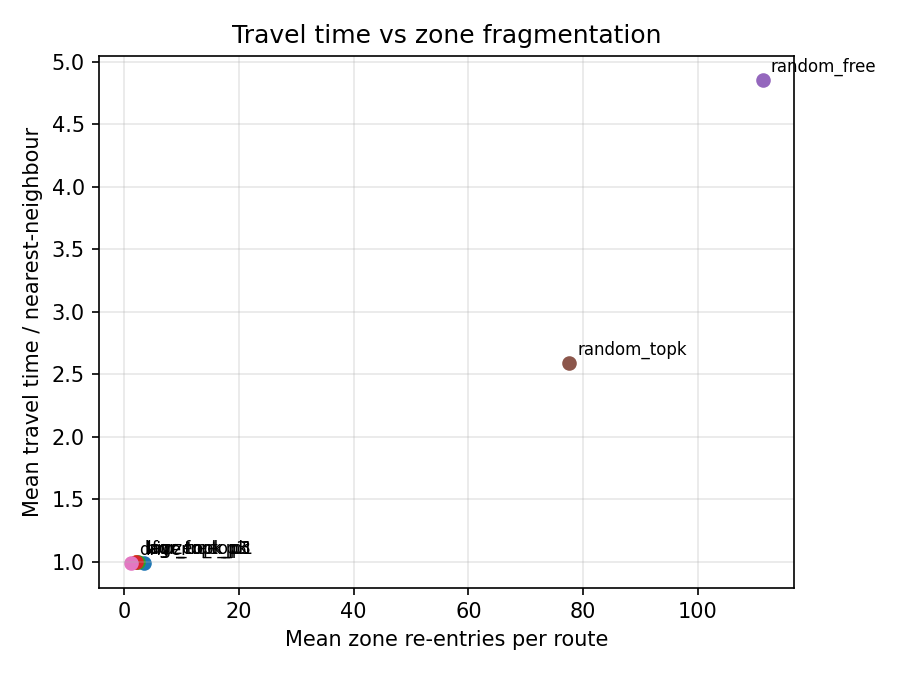

### test_perturb

| label | split | perturb | seeds | routes | mean_time_min | ratio_vs_driver | ratio_vs_nn | ratio_vs_nn_2opt | ratio_vs_ortools | mean_zone_exit | mean_zone_reentry | mean_far_jump | satisfied_zone_exit | satisfied_zone_reentry | satisfied_far_jump | amazon_score | amazon_score_nn | amazon_score_nn_2opt | amazon_score_ortools | mean_latency_ms | p_vs_driver | p_vs_nn | p_vs_nn_2opt | p_vs_ortools | p_vs_frozen_topk |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| frozen_topk | test | 0.2 | 1 | 45 | 169.6809 | 1.0042 | 0.9941 | 1.0562 | 1.1272 | 1.8133 | 3.4000 | 0.0000 | 0.1556 | 0.2222 | 1.0000 | 0.0752 | 0.1055 | 0.0964 | 0.0843 | 182.1813 | 0.8231113822151315 | 0.14342769278198375 | 7.787548383930698e-12 | 1.7053025658242404e-13 |  |
| lagr_free_p3 | test | 0.2 | 1 | 45 | 169.9344 | 1.0054 | 0.9948 | 1.0572 | 1.1283 | 0.9333 | 2.0222 | 0.0000 | 0.3556 | 0.4444 | 1.0000 | 0.0713 | 0.1055 | 0.0964 | 0.0843 | 175.7975 | 0.6546507386780149 | 0.3075094087528214 | 1.4210854715202004e-12 | 1.7053025658242404e-13 | 1.0 |


In [ ]:
from pathlib import Path
from IPython.display import Markdown, Image, display

rep = Path(WORK_DIR) / f"report_{PRESET}"
for sub in ("test", "test_perturb"):
    md_path = rep / sub / "report.md"
    if md_path.exists():
        display(Markdown(f"### {sub}"))
        display(Markdown(md_path.read_text()))
    png = rep / sub / "pareto.png"
    if png.exists():
        display(Image(str(png)))